In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

df = pd.read_csv("/kaggle/input/datasets/mahmodradwan/titanic/titanic_clean.csv")

X = df.drop(columns="target").values
y = df["target"].values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

rf = RandomForestClassifier(n_estimators=50, max_depth=5,
                            oob_score=True, random_state=42)
rf.fit(X_train, y_train.ravel())

def tree_matrix_test(rf, X):
    return np.column_stack([t.predict_proba(X)[:, 1] for t in rf.estimators_])

def tree_matrix_oob(rf, X):
    n = X.shape[0]
    P = np.full((n, len(rf.estimators_)), np.nan)
    for j, (t, idx) in enumerate(zip(rf.estimators_, rf.estimators_samples_)):
        oob = np.setdiff1d(np.arange(n), idx)
        P[oob, j] = t.predict_proba(X[oob])[:, 1]
    row_mean = np.nanmean(P, axis=1, keepdims=True)
    return np.where(np.isnan(P), row_mean, P)

P_train = tree_matrix_oob(rf, X_train)
P_test = tree_matrix_test(rf, X_test)

scaler = StandardScaler()
P_train = scaler.fit_transform(P_train)
P_test = scaler.transform(P_test)

Xb_train = np.c_[np.ones((P_train.shape[0], 1)), P_train]
Xb_test = np.c_[np.ones((P_test.shape[0], 1)), P_test]

print(Xb_train.shape, Xb_test.shape)

(712, 51) (179, 51)


In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def bce_loss(X, y, w):
    p = np.clip(sigmoid(X @ w), 1e-12, 1 - 1e-12)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def evaluate(X, y, w):
    pred = (sigmoid(X @ w) >= 0.5).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    acc = (tp + tn) / len(y)
    prec = tp / (tp + fp) if (tp + fp) else 0
    rec = tp / (tp + fn) if (tp + fn) else 0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0
    return {"Loss": bce_loss(X, y, w), "Accuracy": acc,
            "Precision": prec, "Recall": rec, "F1": f1}

Random Forest (تصويت متساوي) - Test: {'Loss': 0.4581, 'Accuracy': 0.7933, 'Precision': 0.82, 'Recall': 0.5942, 'F1': 0.6891}
                        Loss  Accuracy  Precision  Recall      F1
SGD (Train)           0.3778    0.8610     0.9028  0.7143  0.7975
SGD (Test)            0.6149    0.7430     0.7018  0.5797  0.6349
SGD+Momentum (Train)  0.3792    0.8610     0.9065  0.7106  0.7967
SGD+Momentum (Test)   0.6152    0.7486     0.7069  0.5942  0.6457


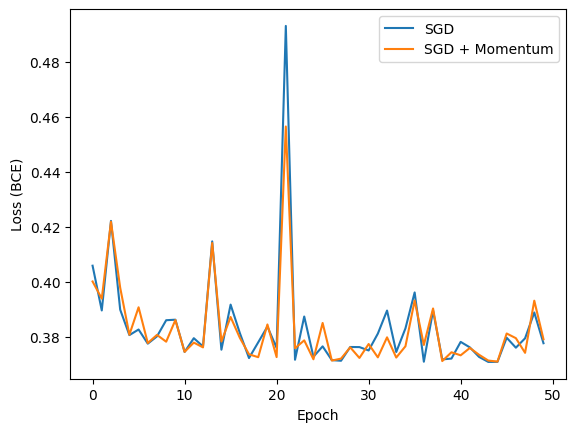

In [3]:
from sklearn.metrics import log_loss, accuracy_score, precision_score, recall_score, f1_score

p_rf = rf.predict_proba(X_test)[:, 1]
pred_rf = (p_rf >= 0.5).astype(int)
print("Random Forest (تصويت متساوي) - Test:",
      {"Loss": round(log_loss(y_test, p_rf), 4),
       "Accuracy": round(accuracy_score(y_test, pred_rf), 4),
       "Precision": round(precision_score(y_test, pred_rf), 4),
       "Recall": round(recall_score(y_test, pred_rf), 4),
       "F1": round(f1_score(y_test, pred_rf), 4)})

def sgd(X, y, lr=0.01, epochs=50, beta=0.0, seed=42):
    rng = np.random.default_rng(seed)
    n = X.shape[0]
    w = np.zeros((X.shape[1], 1))
    v = np.zeros_like(w)
    losses = []
    for _ in range(epochs):
        for i in rng.permutation(n):          # نخلط البيانات كل epoch
            xi, yi = X[i:i+1], y[i:i+1]       # عينة وحدة
            grad = xi.T @ (sigmoid(xi @ w) - yi)
            v = beta * v + grad
            w = w - lr * v
        losses.append(bce_loss(X, y, w))      # الـ loss على كل الـ train
    return w, losses

w_sgd, loss_sgd = sgd(Xb_train, y_train, lr=0.01, beta=0.0)
w_sgdm, loss_sgdm = sgd(Xb_train, y_train, lr=0.001, beta=0.9)

results = pd.DataFrame({
    "SGD (Train)": evaluate(Xb_train, y_train, w_sgd),
    "SGD (Test)": evaluate(Xb_test, y_test, w_sgd),
    "SGD+Momentum (Train)": evaluate(Xb_train, y_train, w_sgdm),
    "SGD+Momentum (Test)": evaluate(Xb_test, y_test, w_sgdm),
}).T.round(4)
print(results)

plt.plot(loss_sgd, label="SGD")
plt.plot(loss_sgdm, label="SGD + Momentum")
plt.xlabel("Epoch"); plt.ylabel("Loss (BCE)"); plt.legend(); plt.show()

# Learning Random Forest Tree Weights with SGD (and Momentum)

## الهدف
تعلّم وزن لكل شجرة من أشجار الـ Random Forest بدل التصويت المتساوي، باستخدام Stochastic Gradient Descent مكتوب من الصفر، ومقارنته مع SGD مع momentum، وذلك للتنبؤ بنجاة ركاب Titanic (target: 1 نجا، 0 ما نجا).

## البيانات
- داتا Titanic بعد التنظيف: 891 صف و7 features.
- قسمت البيانات: 80% تدريب (712 صف) و20% اختبار (179 صف) مع الحفاظ على نسبة الفئات (stratify).
- بنينا Random Forest من 50 شجرة (max_depth = 5)، وطلعنا احتمال كل شجرة للـ class 1، فصار عندنا مصفوفة [عينات × 50 شجرة]. للتدريب استخدمنا احتمالات الـ out-of-bag، وطبقنا StandardScaler على المصفوفة.

## طريقة العمل
- النموذج: p = sigmoid(P @ w)، حيث w وزن كل شجرة، والتصنيف: 1 إذا p >= 0.5.
- الـ Loss: Binary Cross-Entropy.
- SGD: بكل epoch بنخلط البيانات وبنحدّث الأوزان بعد كل عينة وحدة (712 تحديث بالـ epoch).
- قاعدة التحديث: v = beta * v + gradient ثم w = w - lr * v، والـ gradient محسوب على عينة وحدة.
- الـ Loss المرسوم محسوب على كل بيانات التدريب بنهاية كل epoch.
- المقاييس (محسوبة من الصفر من الـ confusion matrix): Accuracy و Precision و Recall و F1.

## الإعدادات
| الطريقة | learning rate | beta | epochs |
|---|---|---|---|
| SGD | 0.01 | 0 | 50 |
| SGD + Momentum | 0.001 | 0.9 | 50 |

## النتائج
| الطريقة | Loss | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|
| Random Forest (تصويت متساوي) - Test | 0.4581 | 0.7933 | 0.8200 | 0.5942 | 0.6891 |
| SGD (Train) | 0.3778 | 0.8610 | 0.9028 | 0.7143 | 0.7975 |
| SGD (Test) | 0.6149 | 0.7430 | 0.7018 | 0.5797 | 0.6349 |
| SGD+Momentum (Train) | 0.3792 | 0.8610 | 0.9065 | 0.7106 | 0.7967 |
| SGD+Momentum (Test) | 0.6152 | 0.7486 | 0.7069 | 0.5942 | 0.6457 |

## الملاحظات
- منحنى الـ Loss بالـ SGD مش ناعم زي الـ GD والـ Mini-batch: بيتذبذب بين حوالي 0.37 و0.42 طول التدريب، وفيه قفزة واضحة عند epoch 21 تقريباً وصل فيها الـ loss لحوالي 0.49. السبب إنه كل تحديث بيعتمد على عينة وحدة، فالـ gradient فيه ضجيج كبير.
- نسخة الـ momentum (البرتقالي) تذبذبها قريب جداً من الـ SGD العادي لأن الـ learning rate الفعلي معها يساوي 0.001 / (1 - 0.9) = 0.01، نفس learning rate الـ SGD العادي. والتذبذب ما اختفى لأن الـ momentum بيمرر جزء من ضجيج التحديثات السابقة.
- الـ SGD ما استقر عند قيمة ثابتة بنهاية الـ 50 epoch، فالنموذج النهائي بيعتمد على آخر عينات شافها. ممكن نخفف التذبذب بتقليل الـ learning rate مع الوقت (learning rate decay).
- الأداء على الاختبار أضعف بوضوح من الـ GD (Test Loss 0.61 مقابل 0.48) ومن الـ Random Forest العادي (0.46). التدريب نفسه كان ممتاز (Accuracy 0.86 وPrecision 0.90)، يعني الأوزان تعلّمت تتأقلم مع بيانات التدريب أكثر من اللازم.
- الفجوة بين التدريب والاختبار كبيرة: الـ Accuracy نزلت من 0.86 لـ 0.74 إلى 0.75، والـ Loss طلع من 0.38 لـ 0.61. الأشجار الخمسين متشابهة بالتنبؤ، فالأوزان الكبيرة اللي بيتعلمها الـ SGD بتضخّم أخطاء الأشجار.
- الـ Precision (0.70) أعلى من الـ Recall (0.58 إلى 0.59)، يعني النموذج بيفوّت حوالي 41% من الناجين الحقيقيين، نفس النمط اللي شفناه بالـ GD.
- فرق الـ Test Accuracy بين الطريقتين (0.7430 مقابل 0.7486) هو عينة وحدة من 179، فهو ضجيج مش تحسن حقيقي.

## الخلاصة
SGD أعطى Test Accuracy حوالي 74% وF1 حوالي 0.64، وهي أضعف من الـ GD (78%) ومن الـ Random Forest العادي (79%). الـ momentum ما غيّر النتيجة لأن الـ learning rate الفعلي نفسه. بهالمسألة الأوزان المتعلمة بالـ SGD بتعمل overfitting، لأن الأشجار قوية أصلاً وتصويتها المتساوي بيشتغل جيد.